# Lab 1 — Linear and logistic regression from scratch

**Mathematics & Statistics for Machine Learning — Albert School, MSc 1 (MSA-DATI07-04)**

In this first lab you build the two most important models of machine learning **with NumPy only**,
on two classic Kaggle projects:

| Part | Kaggle project | Question | Model |
|---|---|---|---|
| A | [Medical Cost Personal Datasets](https://www.kaggle.com/datasets/mirichoi0218/insurance) | How much will an insurance client cost per year? | linear regression |
| B | [Titanic — Machine Learning from Disaster](https://www.kaggle.com/c/titanic) | Did a passenger survive? | logistic regression |

For each model you will write, yourself:

1. the **train / test split**;
2. the **pre-processing** (encoding categories, scaling features — fitted on the training set only);
3. the **model** (the prediction function);
4. the **cost function**;
5. its **gradient**, checked numerically;
6. **gradient descent**;
7. the **evaluation** on data the model has never seen.

At the end you compare your results with `scikit-learn`, which should give the same answer.

**How to work.** Cells marked `TODO` are yours: replace `raise NotImplementedError` with your code.
After each function there is a **checkpoint** cell: run it — if it prints `OK`, move on.
Use the formulas given in the text; every one of them was seen in Lectures 1–3.

## 0. Setup

In [96]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (6, 4)
SEED = 42                                   # one seed for everything: results are reproducible

### Loading the data

The two files come from Kaggle. Three ways to get them, tried in this order:

1. you are **on Kaggle** (the dataset is attached to your notebook): files are under `/kaggle/input/...`;
2. you **downloaded** the CSV from Kaggle and put it next to this notebook (`insurance.csv`, and Titanic's `train.csv`);
3. otherwise, a public copy of the same file is downloaded from GitHub.

In [97]:
import os

def load_csv(candidates, url):
    # Return the first local file that exists, otherwise download a public copy.
    for path in candidates:
        if os.path.exists(path):
            print("loaded from", path)
            return pd.read_csv(path)
    print("downloading a public copy from", url)
    return pd.read_csv(url)

insurance = load_csv(["/kaggle/input/insurance/insurance.csv", "insurance.csv"],
                     "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv")
titanic = load_csv(["/kaggle/input/titanic/train.csv", "train.csv", "titanic.csv"],
                   "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv")
print(insurance.shape, titanic.shape)

loaded from insurance.csv
loaded from titanic.csv
(1338, 7) (891, 12)


---
# Part A — Linear regression: predicting medical costs

An insurer wants to predict the yearly medical **charges** (in USD) of a client from
their age, sex, body-mass index (BMI), number of children, smoking status and region.
The target is a number: this is a **regression** problem.

## A1. Look at the data first

In [98]:
insurance.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.924
1,18,male,33.770,1,no,southeast,1725.552
2,28,male,33.000,3,no,southeast,4449.462
3,33,male,22.705,0,no,northwest,21984.471
4,32,male,28.880,0,no,northwest,3866.855


In [99]:
insurance.describe(include="all")

,age,sex,bmi,children,smoker,region,charges
count,1338.000,1338,1338.000,1338.000,1338,1338,1338.000
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,676,NaN,NaN,1064,364,NaN
mean,39.207,NaN,30.663,1.095,NaN,NaN,13270.422
std,14.050,NaN,6.098,1.205,NaN,NaN,12110.011
min,18.000,NaN,15.960,0.000,NaN,NaN,1121.874
25%,27.000,NaN,26.296,0.000,NaN,NaN,4740.287
50%,39.000,NaN,30.400,1.000,NaN,NaN,9382.033
75%,51.000,NaN,34.694,2.000,NaN,NaN,16639.913


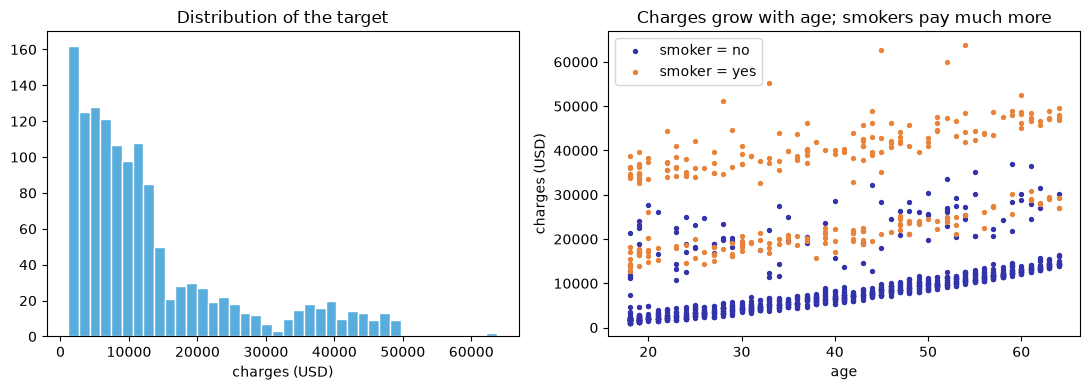

In [100]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(insurance["charges"], bins=40, color="#59ADDC", edgecolor="white")
axes[0].set_xlabel("charges (USD)"); axes[0].set_title("Distribution of the target")
for status, color in [("no", "#3333AB"), ("yes", "#E8833A")]:
    d = insurance[insurance["smoker"] == status]
    axes[1].scatter(d["age"], d["charges"], s=8, color=color, label=f"smoker = {status}")
axes[1].set_xlabel("age"); axes[1].set_ylabel("charges (USD)"); axes[1].legend()
axes[1].set_title("Charges grow with age; smokers pay much more")
plt.tight_layout(); plt.show()

**Question A1.** From the two plots: which feature seems the most important? Is the target symmetric?
Write two sentences in the markdown cell below.

*Your answer:* Smockers seems to be a better feature. There is a greater delta between no and smockers in terms of charges at similar age. Whereas for age, there is a smaller positive association with charges. Concerning Target's distribution, it is not similar but right skewed. Indeed, there is many low charges and a few high charges.

## A2. Pre-processing

A linear model only understands **numbers**. We must:

* turn the categories (`sex`, `smoker`, `region`) into 0/1 columns (**one-hot encoding**),
  dropping one level per category to avoid the *dummy-variable trap* (Lecture 2);
* split the data into a **training set** (to learn) and a **test set** (to evaluate, used only once at the end);
* **standardise** each feature, $x \leftarrow (x-\text{mean})/\text{std}$, with the mean and std computed **on the training set only**
  (otherwise information from the test set leaks into the model).

In [104]:
X_df = pd.get_dummies(insurance.drop(columns="charges"), drop_first=True, dtype=float)
X_df["smoker_bmi"] = X_df["smoker_yes"] * X_df["bmi"]
y_ins = insurance["charges"].to_numpy()
feature_names = list(X_df.columns)
X_ins = X_df.to_numpy()
print(feature_names)
print(X_ins.shape, y_ins.shape)

['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest', 'smoker_bmi']
(1338, 9) (1338,)


### TODO A2.1 — a train/test split from scratch

Write `train_test_split(X, y, test_size, seed)` that

1. draws a random permutation of the row indices (`np.random.default_rng(seed).permutation(n)`);
2. puts the first `round(test_size * n)` shuffled rows in the test set and the rest in the training set;
3. returns `X_train, X_test, y_train, y_test`.

*Why shuffle?* The file may be sorted (by date, by region…): the test set must look like the training set.

In [102]:
def train_test_split(X, y, test_size=0.2, seed=SEED):
    n = X.shape[0]

    indices = np.random.default_rng(seed).permutation(n)

    n_test = round(test_size*n)

    test_indices = indices[:n_test]
    train_indices = indices[n_test:]

    X_train = X[train_indices]
    X_test = X[test_indices]
    y_train = y[train_indices]
    y_test = y[test_indices]

    return X_train, X_test, y_train, y_test


In [105]:
# Checkpoint
Xtr_ins, Xte_ins, ytr_ins, yte_ins = train_test_split(X_ins, y_ins, test_size=0.2)
assert Xtr_ins.shape == (1070, 9) and Xte_ins.shape == (268, 9), "wrong sizes"
assert len(set(map(tuple, Xtr_ins)) & set(map(tuple, Xte_ins))) <= 1, "train and test overlap"
print("OK —", len(ytr_ins), "training rows,", len(yte_ins), "test rows")

OK — 1070 training rows, 268 test rows


### TODO A2.2 — standardisation fitted on the training set

Write a function that returns the standardised training set **and** the test set transformed with the
**training** mean and standard deviation.

In [106]:
def standardise(X_train, X_test):
    mean = X_train.mean(axis=0)
    std = X_train.std(axis=0)

    std = np.where(std==0, 1, std)

    Z_train = (X_train - mean) / std
    Z_test = (X_test - mean) / std

    return Z_train, Z_test

In [107]:
# Checkpoint
Ztr_ins, Zte_ins = standardise(Xtr_ins, Xte_ins)
assert np.allclose(Ztr_ins.mean(axis=0), 0) and np.allclose(Ztr_ins.std(axis=0), 1)
assert not np.allclose(Zte_ins.mean(axis=0), 0), "the test set must use the TRAINING mean, not its own"
print("OK — training features have mean 0 and std 1")

OK — training features have mean 0 and std 1


## A3. The model and its cost

For a client with (standardised) features $\mathbf x\in\mathbb R^d$, the model predicts
$$
\hat y = \mathbf w^\top \mathbf x + b .
$$
For all $m$ clients at once, with the matrix $X$ ($m\times d$, one client per row): $\hat{\mathbf y} = X\mathbf w + b$.

The **cost** is the mean squared error (with a $\tfrac12$ that makes the gradient cleaner):
$$
J(\mathbf w, b) = \frac{1}{2m}\sum_{i=1}^m \big(\hat y_i - y_i\big)^2 .
$$

### TODO A3.1 — prediction and cost

Use matrix operations only (`@`, `np.mean`), **no Python loop over clients**.

In [108]:
def predict_linear(X, w, b):
    return X@w + b


def cost_linear(X, y, w, b):
    predictions = predict_linear(X, w, b)
    error = predictions - y
    return 0.5*np.mean(error**2)

In [109]:
# Checkpoint
w0, b0 = np.zeros(Ztr_ins.shape[1]), 0.0
J0 = cost_linear(Ztr_ins, ytr_ins, w0, b0)
assert np.isclose(J0, np.mean(ytr_ins ** 2) / 2)
print(f"OK — cost of the all-zero model: {J0:,.0f}")

OK — cost of the all-zero model: 165,004,136


## A4. The gradient

Differentiating $J$ (Lecture 2–3):
$$
\frac{\partial J}{\partial \mathbf w} = \frac1m X^\top(\hat{\mathbf y}-\mathbf y),
\qquad
\frac{\partial J}{\partial b} = \frac1m\sum_{i=1}^m(\hat y_i - y_i).
$$
In words: *prediction error × feature*, averaged over clients.

### TODO A4.1 — the gradient

In [110]:
def gradient_linear(X, y, w, b):
    prediction = predict_linear(X, w, b)
    error = prediction - y
    m = X.shape[0]

    dJ_dw = X.T@error/m
    dJ_db = np.mean(error)
    return dJ_dw, dJ_db

### Always check a gradient numerically

A bug in a gradient does not crash the code: gradient descent just converges to a wrong answer.
We compare each partial derivative with a **finite difference**
$\dfrac{J(w_j+h)-J(w_j-h)}{2h}$. This function is given.

In [111]:
def numerical_gradient(cost, X, y, w, b, h=1e-4):
    dw = np.zeros_like(w)
    for j in range(len(w)):
        e = np.zeros_like(w); e[j] = h
        dw[j] = (cost(X, y, w + e, b) - cost(X, y, w - e, b)) / (2 * h)
    db = (cost(X, y, w, b + h) - cost(X, y, w, b - h)) / (2 * h)
    return dw, db

# Checkpoint: compare at a random point
rng = np.random.default_rng(0)
w_test, b_test = rng.normal(size=Ztr_ins.shape[1]) * 1000, 500.0
dw, db = gradient_linear(Ztr_ins, ytr_ins, w_test, b_test)
dw_num, db_num = numerical_gradient(cost_linear, Ztr_ins, ytr_ins, w_test, b_test)
rel = np.linalg.norm(np.r_[dw - dw_num, db - db_num]) / np.linalg.norm(np.r_[dw_num, db_num])
assert rel < 1e-6, f"gradient wrong, relative error {rel:.1e}"
print(f"OK — relative error {rel:.1e}")

OK — relative error 2.0e-08


## A5. Gradient descent

Start from $\mathbf w=\mathbf 0$, $b=0$ and repeat
$$
\mathbf w \leftarrow \mathbf w - \alpha\,\frac{\partial J}{\partial \mathbf w},\qquad
b \leftarrow b - \alpha\,\frac{\partial J}{\partial b}.
$$
$\alpha$ is the **learning rate**. Keep the cost of every iteration to draw the learning curve.

### TODO A5.1 — the gradient-descent loop

In [112]:
def gradient_descent(X, y, cost, gradient, alpha=0.1, n_iters=1000):
    w, b = np.zeros(X.shape[1]), 0.0
    history = []
    
    for it in range(n_iters):
        dJ_dw, dJ_db = gradient(X, y, w, b)

        w = w - alpha * dJ_dw
        b = b - alpha * dJ_db

        history.append(cost(X, y, w, b))
        
    return w, b, np.array(history)

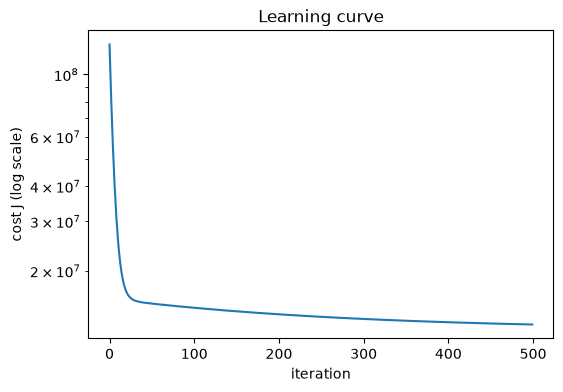

final training cost: 12,882,058
OK


In [113]:
w_gd, b_gd, hist = gradient_descent(Ztr_ins, ytr_ins, cost_linear, gradient_linear, alpha=0.1, n_iters=500)
plt.plot(hist); plt.yscale("log")
plt.xlabel("iteration"); plt.ylabel("cost J (log scale)"); plt.title("Learning curve")
plt.show()
print(f"final training cost: {hist[-1]:,.0f}")
assert hist[-1] < hist[0] and np.all(np.diff(hist) <= 1e-6 * hist[:-1]), "the cost should decrease at every step"
print("OK")

### Experiment A5.2 — the learning rate

Run gradient descent with $\alpha = 0.001,\ 0.1,\ 1.2,\ 1.4$ (100 iterations each) and plot the four learning curves.
What happens when $\alpha$ is too small? too large?

*Hint (explained in Lecture 8):* gradient descent diverges when $\alpha > 2/L$, where $L$ is the largest eigenvalue of
$X^\top X/m$. Check it with `np.linalg.eigvalsh(Ztr_ins.T @ Ztr_ins / len(Ztr_ins)).max()`.

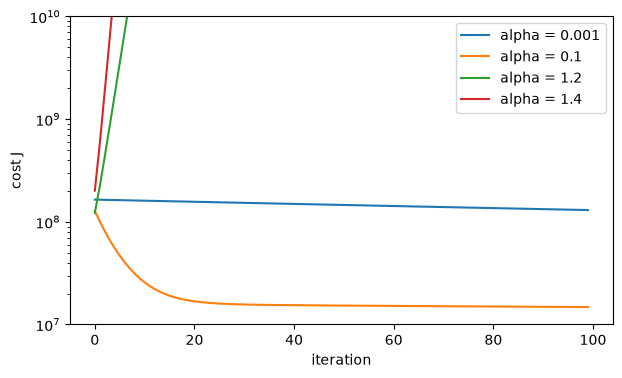

In [114]:
plt.figure(figsize=(7, 4))
for alpha in [0.001, 0.1, 1.2, 1.4]:
    w, b, history = gradient_descent(
        Ztr_ins,
        ytr_ins,
        cost_linear,
        gradient_linear,
        alpha=alpha,
        n_iters=100
    )
    plt.plot(history, label=f"alpha = {alpha}")
        
    
plt.yscale("log"); plt.ylim(1e7, 1e10); plt.xlabel("iteration"); plt.ylabel("cost J"); plt.legend(); plt.show()

*Your observations:*

α = 0.001: learns very slowly, the cost remains high after 100 iterations
α = 0.1 : converges steadily to a low cost
α = 1.2 : reaches approx. the same low cost but much faster
α = 1.4 : initially improves, then diverges because steps are too large

## A6. Evaluation on the test set

Three numbers, all computed on the **test** set:

* **RMSE** $=\sqrt{\frac1m\sum(\hat y_i-y_i)^2}$ — a typical error, in USD;
* **MAE** $=\frac1m\sum|\hat y_i-y_i|$ — average absolute error, in USD;
* $R^2 = 1-\dfrac{\sum(\hat y_i-y_i)^2}{\sum(y_i-\bar y)^2}$ — share of the variation explained (Lecture 2).

### TODO A6.1 — regression metrics

In [115]:
def regression_metrics(y_true, y_pred):
    RMSE = np.mean((y_pred - y_true)**2)**0.5
    MAE = np.mean(abs(y_pred - y_true))
    R_2 = 1 - (np.sum((y_pred - y_true)**2)/np.sum((y_true - y_true.mean())**2))

    return {"RMSE": RMSE, "MAE": MAE, "R2": R_2}

In [116]:
w_gd, b_gd, _ = gradient_descent(Ztr_ins, ytr_ins, cost_linear, gradient_linear, alpha=0.1, n_iters=2000)
res = pd.DataFrame({"train": regression_metrics(ytr_ins, predict_linear(Ztr_ins, w_gd, b_gd)),
                    "test": regression_metrics(yte_ins, predict_linear(Zte_ins, w_gd, b_gd))})
res

,train,test
RMSE,4972.392,4221.660
MAE,2992.372,2710.191
R2,0.837,0.857


**Baseline.** Is the model useful at all? Compare with the dumbest model: predict the **training mean** for every client. Our model is better. We observe that our average error is about 3954$ compared to 8321$ for the baseline model

In [58]:
baseline = np.full_like(yte_ins, ytr_ins.mean())
pd.Series(regression_metrics(yte_ins, baseline), name="baseline (test)")

RMSE    11183.935
MAE      8321.960
R2         -0.001
Name: baseline (test), dtype: float64

## A7. Same answer as the closed form and as scikit-learn?

Linear regression also has a **closed form**: the normal equations (Lecture 2). Add a column of ones for $b$ and solve
with `np.linalg.lstsq`. Then fit `sklearn.linear_model.LinearRegression`. All three should agree.

In [60]:
from sklearn.linear_model import LinearRegression

A = np.c_[np.ones(len(ytr_ins)), Ztr_ins]
theta = np.linalg.lstsq(A, ytr_ins, rcond=None)[0]           # [b, w_1, ..., w_d]
skl = LinearRegression().fit(Ztr_ins, ytr_ins)

comparison = pd.DataFrame({"gradient descent": np.r_[b_gd, w_gd],
                           "normal equations": theta,
                           "scikit-learn": np.r_[skl.intercept_, skl.coef_]},
                          index=["intercept"] + feature_names)
comparison

KeyboardInterrupt: 

## A8. What did the model learn?

Because the features are standardised, each weight is the change in predicted charges (USD) for an increase of
**one standard deviation** of that feature, the others held fixed. Weights can therefore be compared.

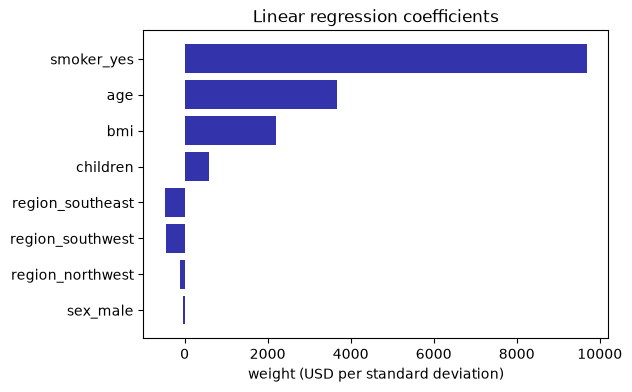

In [61]:
order = np.argsort(np.abs(w_gd))
plt.barh(np.array(feature_names)[order], w_gd[order], color="#3333AB")
plt.xlabel("weight (USD per standard deviation)"); plt.title("Linear regression coefficients"); plt.show()

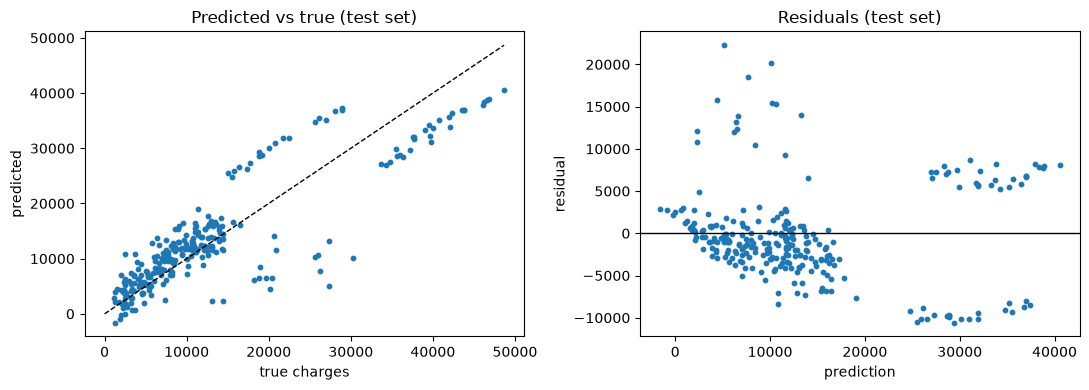

In [62]:
pred_te = predict_linear(Zte_ins, w_gd, b_gd)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(yte_ins, pred_te, s=10); lim = [0, yte_ins.max()]
axes[0].plot(lim, lim, "k--", lw=1); axes[0].set_xlabel("true charges"); axes[0].set_ylabel("predicted")
axes[0].set_title("Predicted vs true (test set)")
axes[1].scatter(pred_te, yte_ins - pred_te, s=10); axes[1].axhline(0, color="k", lw=1)
axes[1].set_xlabel("prediction"); axes[1].set_ylabel("residual"); axes[1].set_title("Residuals (test set)")
plt.tight_layout(); plt.show()

**Questions A8.**

1. Which feature has the largest effect? Translate its weight into a sentence an insurer would understand.
2. The residual plot shows clear groups. Look back at the scatter plot of section A1: which interaction between two
   features is the straight line missing? *(Hint: does BMI matter in the same way for smokers and non-smokers?)*
3. **Bonus.** Add a column `smoker_yes * bmi` to `X_df`, rerun the whole part A, and compare the test $R^2$.

*Your answers:*
1. As observed in the bar chart, the main and most important feature to determine the charges is knowing is the customer is a smoker or not. It is 2.5x more important than the second one whuch is the age. That follows what we observe in the first graph at the beggining of this lab.
2. As observed in the residual plot, there are clear groups showing that the model does not capture all the relationships between the features. The missing interaction is between BMI and smoking: a higher BMI is associated with a much larger increase in charges for smokers than for non-smokers, while our model assumes the same BMI effect for both
3. Without : R2 = 0.756 and with R2 = 0.857; variance is better explained with the relationship between smoker and BMI.


---
# Part B — Logistic regression: who survived the Titanic?

The target is now **yes/no**: `Survived` = 1 or 0. This is a **classification** problem. We want the model to output a
**probability** of survival.

## B1. Look at the data

In [117]:
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.250,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.283,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.925,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.100,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.050,NaN,S


missing values per column:
Age         177
Cabin       687
Embarked      2
dtype: int64

survival rate: 0.384


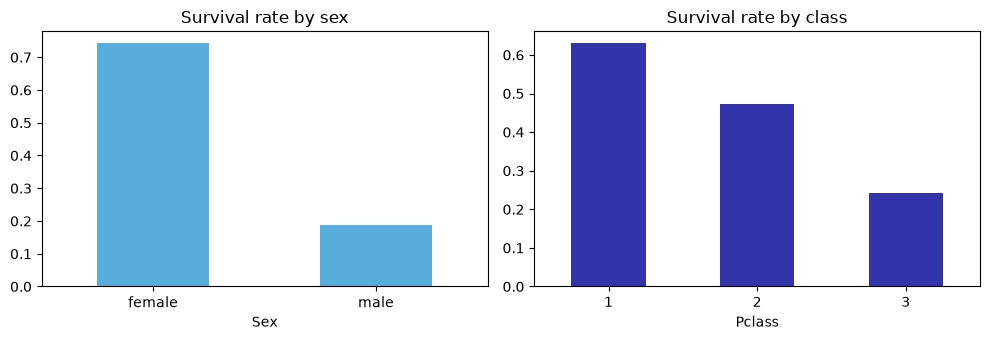

In [118]:
print("missing values per column:"); print(titanic.isna().sum()[titanic.isna().sum() > 0])
print("\nsurvival rate:", round(titanic["Survived"].mean(), 3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
titanic.groupby("Sex")["Survived"].mean().plot.bar(ax=axes[0], color="#59ADDC", rot=0, title="Survival rate by sex")
titanic.groupby("Pclass")["Survived"].mean().plot.bar(ax=axes[1], color="#3333AB", rot=0, title="Survival rate by class")
plt.tight_layout(); plt.show()

## B2. Pre-processing

We keep 7 features: `Pclass, Sex, Age, SibSp, Parch, Fare, Embarked`.

* `Age` has missing values: fill them with the **median age of the training set**;
  `Embarked` has 2 missing values: fill them with the most frequent port.
* `Pclass`, `Sex`, `Embarked` are categories: one-hot encode them (drop one level each).
* Split **before** computing the median and the scaling statistics, so the test set stays unseen.

In [119]:
cols = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
raw = titanic[cols].copy()
raw["Pclass"] = raw["Pclass"].astype(str)                 # a category, not a quantity
y_tit = titanic["Survived"].to_numpy().astype(float)

# split the ROW INDICES with your function, then build the two tables
idx_tr, idx_te, _, _ = train_test_split(np.arange(len(raw)), y_tit, test_size=0.2)
raw_tr, raw_te = raw.iloc[idx_tr].copy(), raw.iloc[idx_te].copy()
ytr_tit, yte_tit = y_tit[idx_tr], y_tit[idx_te]

# imputation with TRAINING statistics
age_median = raw_tr["Age"].median()
port_mode = raw_tr["Embarked"].mode()[0]
for d in (raw_tr, raw_te):
    d["Age"] = d["Age"].fillna(age_median)
    d["Embarked"] = d["Embarked"].fillna(port_mode)

# one-hot encoding with the same columns in train and test
Xtr_df = pd.get_dummies(raw_tr, drop_first=True, dtype=float)
Xte_df = pd.get_dummies(raw_te, drop_first=True, dtype=float).reindex(columns=Xtr_df.columns, fill_value=0.0)
tit_features = list(Xtr_df.columns)
Ztr_tit, Zte_tit = standardise(Xtr_df.to_numpy(), Xte_df.to_numpy())
print(tit_features)
print(Ztr_tit.shape, Zte_tit.shape, "| survival rate train/test:", ytr_tit.mean().round(3), yte_tit.mean().round(3))

['Age', 'SibSp', 'Parch', 'Fare', 'Pclass_2', 'Pclass_3', 'Sex_male', 'Embarked_Q', 'Embarked_S']
(713, 9) (178, 9) | survival rate train/test: 0.369 0.444


## B3. The model: a score squashed into a probability

Linear regression could predict $-0.3$ or $1.4$: not probabilities. Logistic regression computes a score
$z=\mathbf w^\top\mathbf x+b$ and squashes it with the **sigmoid**
$$
\sigma(z)=\frac{1}{1+e^{-z}}\in(0,1),\qquad \hat p=\mathbb P(\text{survived}\mid\mathbf x)=\sigma(\mathbf w^\top\mathbf x+b).
$$

### TODO B3.1 — sigmoid and prediction

In [122]:
def sigmoid(z):
    return 1/(1+np.exp(-z))


def predict_proba(X, w, b):
    z = X@w + b
    return sigmoid(z)

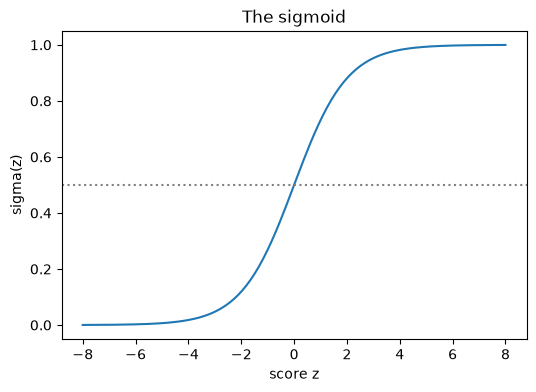

OK


In [123]:
# Checkpoint
assert np.isclose(sigmoid(0), 0.5) and sigmoid(10) > 0.9999 and sigmoid(-10) < 1e-4
z = np.linspace(-8, 8, 200)
plt.plot(z, sigmoid(z)); plt.axhline(0.5, ls=":", color="gray"); plt.xlabel("score z"); plt.ylabel("sigma(z)")
plt.title("The sigmoid"); plt.show()
print("OK")

## B4. The cost: binary cross-entropy

Squared error on probabilities works badly (Lecture 3). We use the **cross-entropy** (log-loss):
$$
J(\mathbf w,b)=-\frac1m\sum_{i=1}^m\Big[y_i\log\hat p_i+(1-y_i)\log(1-\hat p_i)\Big].
$$
If a passenger survived ($y=1$) and the model said $\hat p=0.01$, the cost is $-\log 0.01\approx4.6$: confident mistakes are expensive.

**Numerical detail.** $\log 0$ is $-\infty$: clip the probabilities to $[\varepsilon, 1-\varepsilon]$ with $\varepsilon=10^{-12}$ before taking logs.

### TODO B4.1 — cross-entropy

In [124]:
def cost_logistic(X, y, w, b, eps=1e-12):
    m = X.shape[0]

    cost = -(1/m)*sum(y*np.log(predict_proba(X, w, b))+(1-y)*np.log(1-predict_proba(X, w, b)))
    return cost 

In [125]:
# Checkpoint: with w = 0 and b = 0 the model says p = 0.5 for everyone, so J = log 2
J0 = cost_logistic(Ztr_tit, ytr_tit, np.zeros(Ztr_tit.shape[1]), 0.0)
assert np.isclose(J0, np.log(2)), J0
print(f"OK — initial cost {J0:.4f} = log 2")

OK — initial cost 0.6931 = log 2


## B5. The gradient — the same form as for linear regression!

With the sigmoid and the cross-entropy, the derivatives simplify beautifully (derived in Lecture 3):
$$
\frac{\partial J}{\partial \mathbf w} = \frac1m X^\top(\hat{\mathbf p}-\mathbf y),
\qquad
\frac{\partial J}{\partial b} = \frac1m\sum_{i=1}^m(\hat p_i - y_i).
$$
Again *prediction error × feature*. Only the prediction changed.

### TODO B5.1 — the gradient, then check it

In [128]:
def gradient_logistic(X, y, w, b):
    m = X.shape[0]

    dJ_dw = (1/m)* X.T @(predict_proba(X, w, b) - y)
    dJ_db = (1/m)* sum(predict_proba(X, w, b) - y)

    return dJ_dw, dJ_db

In [129]:
# Checkpoint
w_test, b_test = rng.normal(size=Ztr_tit.shape[1]), 0.3
dw, db = gradient_logistic(Ztr_tit, ytr_tit, w_test, b_test)
dw_num, db_num = numerical_gradient(cost_logistic, Ztr_tit, ytr_tit, w_test, b_test)
rel = np.linalg.norm(np.r_[dw - dw_num, db - db_num]) / np.linalg.norm(np.r_[dw_num, db_num])
assert rel < 1e-6, f"gradient wrong, relative error {rel:.1e}"
print(f"OK — relative error {rel:.1e}")

OK — relative error 5.3e-10


## B6. Train with *your* gradient descent

No new code: the function `gradient_descent` of Part A works for any cost and gradient.
We also track the **test** cost to see whether the model over-fits.

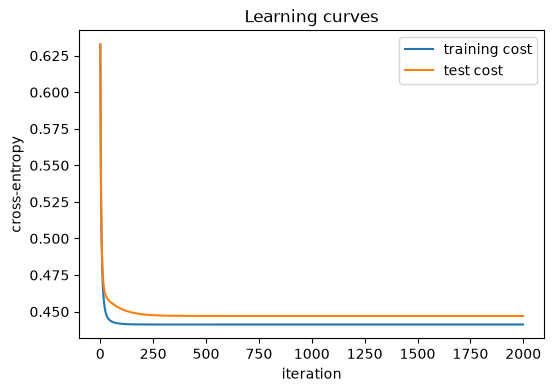

final cost — train 0.4412, test 0.4470


In [130]:
w_lr, b_lr, hist_tr = gradient_descent(Ztr_tit, ytr_tit, cost_logistic, gradient_logistic, alpha=0.5, n_iters=2000)

hist_te = []                                          # test cost along the way (for the plot only)
w, b = np.zeros(Ztr_tit.shape[1]), 0.0
for it in range(2000):
    dw, db = gradient_logistic(Ztr_tit, ytr_tit, w, b)
    w, b = w - 0.5 * dw, b - 0.5 * db
    hist_te.append(cost_logistic(Zte_tit, yte_tit, w, b))

plt.plot(hist_tr, label="training cost"); plt.plot(hist_te, label="test cost")
plt.xlabel("iteration"); plt.ylabel("cross-entropy"); plt.legend(); plt.title("Learning curves"); plt.show()
print(f"final cost — train {hist_tr[-1]:.4f}, test {hist_te[-1]:.4f}")

## B7. Evaluation: from probabilities to decisions

Predict "survived" when $\hat p\ge 0.5$. Then count, on the **test** set:

|  | predicted 0 | predicted 1 |
|---|---|---|
| **actual 0** | TN (true negative) | FP (false positive) |
| **actual 1** | FN (false negative) | TP (true positive) |

* **accuracy** $=\dfrac{TP+TN}{m}$; **precision** $=\dfrac{TP}{TP+FP}$ (when we say "survived", how often right?);
* **recall** $=\dfrac{TP}{TP+FN}$ (of the survivors, how many did we find?); **F1** $=2\dfrac{\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$.

### TODO B7.1 — classification metrics

In [131]:
def classification_metrics(y_true, p_hat, threshold=0.5):
    y_pred = (p_hat >= threshold).astype(float)
    
    tp = np.sum((y_true == 1) & (y_pred == 1))
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    accuracy = (tp + tn) / len(y_true)
    precision = tp / (tp + fp) if tp + fp > 0 else 0.0
    recall = tp / (tp + fn) if tp + fn > 0 else 0.0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0.0
    )

    confusion = pd.DataFrame([[tn, fp], [fn, tp]], index=["actual 0", "actual 1"], columns=["pred 0", "pred 1"])
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "F1": f1}, confusion

In [132]:
scores_te, confusion_te = classification_metrics(yte_tit, predict_proba(Zte_tit, w_lr, b_lr))
scores_tr, _ = classification_metrics(ytr_tit, predict_proba(Ztr_tit, w_lr, b_lr))
print(confusion_te)
pd.DataFrame({"train": scores_tr, "test": scores_te})

          pred 0  pred 1
actual 0      87      12
actual 1      22      57


,train,test
accuracy,0.805,0.809
precision,0.763,0.826
recall,0.684,0.722
F1,0.721,0.770


**Baseline.** A model that predicts "died" for everybody — what accuracy does it get on the test set?

In [133]:
print("majority-class accuracy:", round(np.mean(yte_tit == 0), 3))

majority-class accuracy: 0.556


### Experiment B7.2 — moving the threshold

A rescue team might prefer to find **more** survivors even at the cost of false alarms.
Compute precision and recall on the test set for thresholds from 0.1 to 0.9 and plot them.

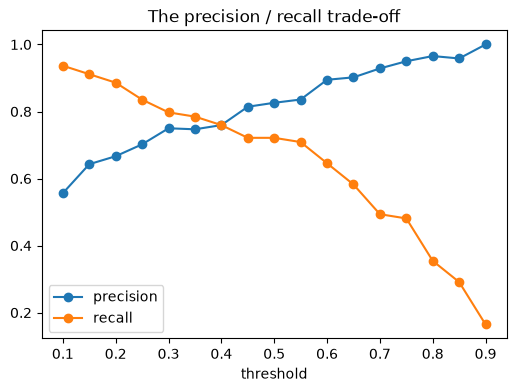

In [135]:
thresholds = np.linspace(0.1, 0.9, 17)
P, R = [], []
p_hat = predict_proba(Zte_tit, w_lr, b_lr)

for t in thresholds:
    scores, _ = classification_metrics(yte_tit, p_hat, threshold=t)
    P.append(scores["precision"])
    R.append(scores["recall"])
    
plt.plot(thresholds, P, "o-", label="precision"); plt.plot(thresholds, R, "o-", label="recall")
plt.xlabel("threshold"); plt.legend(); plt.title("The precision / recall trade-off"); plt.show()

## B8. Compare with scikit-learn and interpret

`LogisticRegression` with a huge `C` (that is, no penalty) minimises exactly our cost.

**Odds ratio.** Increasing a (standardised) feature by one standard deviation multiplies the **odds**
$\hat p/(1-\hat p)$ of survival by $e^{w_j}$.

In [137]:
from sklearn.linear_model import LogisticRegression

skl_lr = LogisticRegression(C=1e10, max_iter=10_000).fit(Ztr_tit, ytr_tit)   # C huge = no penalty
table = pd.DataFrame({"our weight": w_lr, "sklearn weight": skl_lr.coef_[0],
                      "odds ratio e^w": np.exp(w_lr)}, index=tit_features)
print(f"intercept: ours {b_lr:.4f}, sklearn {skl_lr.intercept_[0]:.4f}")
print(f"test accuracy: ours {scores_te['accuracy']:.3f}, sklearn {skl_lr.score(Zte_tit, yte_tit):.3f}")
table.sort_values("our weight")
print("Train accuracy:", scores_tr["accuracy"])
print("Test accuracy:", scores_te["accuracy"])

intercept: ours -0.7303, sklearn -0.7304
test accuracy: ours 0.809, sklearn 0.809
Train accuracy: 0.8050490883590463
Test accuracy: 0.8089887640449438


**Questions B8.**

1. Which feature increases the chance of survival the most? Which decreases it the most? Is this consistent with
   "women and children first"?
2. The odds ratio of `Sex_male` is about 0.28. Write one sentence that explains it to a non-specialist.
3. Compare training and test accuracy. Does the model over-fit?

*Your answers:*
1. The feature that increases the most the chance of survival is the sex. Being a woman is a massive advantage and men have fewer chance of surviving. The age feature is important and negative meaning younger people tend to have a greater chance to survice. That is consistent with women and children first. 
2. For passengers with otherwise identical characteristics, the ratio of survival probability to death probability is about 72% lower for men than for women
3. Test accuracy is slightly higher than then training one, that means model generalize well and it doesn't mean it is overfitting, it can be random. 

---
# Summary

| step | linear regression | logistic regression |
|---|---|---|
| prediction | $\hat y = X\mathbf w+b$ | $\hat p=\sigma(X\mathbf w+b)$ |
| cost | mean squared error | cross-entropy |
| gradient | $\frac1m X^\top(\hat{\mathbf y}-\mathbf y)$ | $\frac1m X^\top(\hat{\mathbf p}-\mathbf y)$ |
| training | gradient descent (same function!) | gradient descent (same function!) |
| evaluation | RMSE, MAE, $R^2$ | accuracy, precision, recall, F1 |

The workflow never changes: **split → pre-process with training statistics → model → cost → gradient (checked) →
gradient descent → evaluate on the test set → compare with a baseline**.

## Going further (optional)

1. **Log target.** Medical charges are skewed. Fit the linear model on $\log(\text{charges})$, convert predictions
   back with `np.exp`, and compare the test MAE.
2. **Regularisation.** Add $\frac{\lambda}{2m}\lVert\mathbf w\rVert^2$ to both costs. What changes in the gradient?
   Try $\lambda\in\{0.1,1,10\}$ (this is ridge — Lecture 7).
3. **Mini-batches.** Modify `gradient_descent` to use a random batch of 32 rows per step (SGD — Lecture 8).
4. **Kaggle submission.** Apply your Titanic model to Kaggle's `test.csv` (same pre-processing, training statistics!) and submit.